In [25]:
import numpy as np
import pickle
import matplotlib.pyplot as plt

In [26]:
def transpose(x):
    output = []
    for x_use in x[:1]:
        x_reshaped = np.reshape(np.transpose(np.reshape(x_use[0:512], [512//8,8])), [512])
        output.append(x_reshaped)
    return(np.array(output))

In [27]:
np.array([512//8,8])

array([64,  8])

In [28]:
with open('/lustre/rbyrne/feng_outputs_coeff_ramp.pkl', 'rb') as fh:
    d = pickle.load(fh)
    din = transpose(d['din']) / 2**17
    coeff = transpose(d['coeff']) / 2**2
    dout = transpose(d['dout']) / 2**3
    dout_full = transpose(d['dout_full']) / 2**19

In [29]:
transpose(d['dout_full'])

array([[-313000.     +0.j,  -24000.-144000.j,   51051.     +0.j,
         -46092. +14028.j,  -10030. +56168.j,  -11033. +80240.j,
          12048. +84336.j,   46230. +62310.j, -106636. +67402.j,
           3021. +64448.j,   54378. +46322.j,  -68544.  +2016.j,
        -115026. -34306.j,   -2020.  -8080.j,  -44440. +14140.j,
         -52572. +32352.j,    2024. -42504.j,  -30390. +22286.j,
         -86190.     +0.j,   61854. +17238.j,   48720. +50750.j,
          24384.  -9144.j,   35595. -42714.j,    2034. -26442.j,
          -8144. -90602.j,  -63178.  -3057.j,   87720.  +8160.j,
         -56155. -53092.j,  -38798. -84743.j,  -23506. -10220.j,
         -10230.  -4092.j,   38912. +73728.j,  -58425. -33825.j,
         -23575. +34850.j,   40014. -34884.j,   22594. -73944.j,
          32896. -45232.j,  -55512. +86352.j,   22638. -20580.j,
          30900. -62830.j,  -95883. +49488.j,   18576.+113520.j,
          48504. -26832.j, -121894. -61980.j,   53768. +37224.j,
          41400. -37260.j

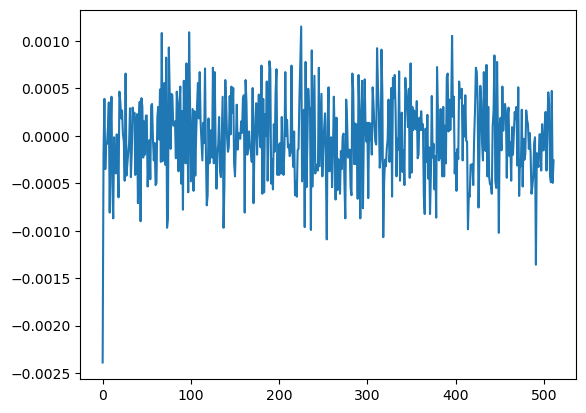

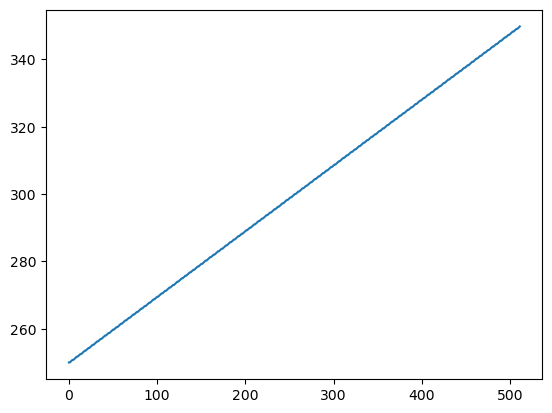

In [30]:
plt.plot(np.mean(din, axis=0))
#plt.ylim((-1e-5, 1e-5))
plt.show()

plt.plot(np.mean(coeff, axis=0))
plt.show()

0.0 0.0


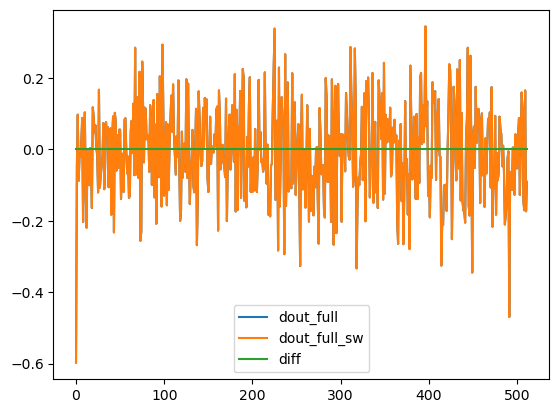

In [34]:
dout_full_sw = din * coeff
plt.plot(np.mean(dout_full, axis=0).real, label='dout_full')
plt.plot(np.mean(dout_full_sw, axis=0).real, label='dout_full_sw')
plt.plot(np.mean(dout_full - dout_full_sw, axis=0).real, label='diff')
print(np.max((dout_full - dout_full_sw).real), np.max((dout_full - dout_full_sw).imag))
#plt.ylim(-.03, .03)
plt.legend()
plt.show()

0.0 0.0


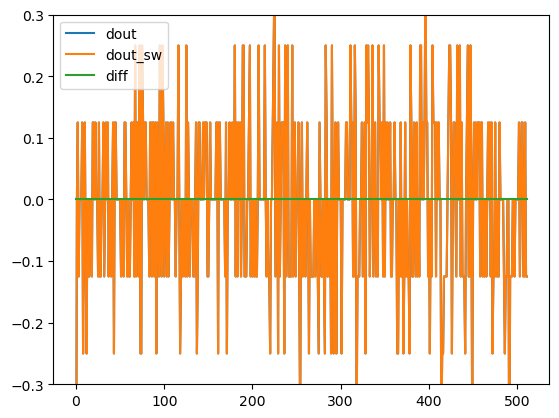

In [32]:
dout_sw = np.round(din * coeff * 2**3) / 2**3
plt.plot(np.mean(dout.real, axis=0), label='dout')
plt.plot(np.mean(dout_sw.real, axis=0), label='dout_sw')
plt.plot(np.mean(dout - dout_sw, axis=0).real, label='diff')
print(np.max((dout - dout_sw).real), np.max((dout - dout_sw).imag))
plt.ylim(-.3, .3)

plt.legend()
plt.show()

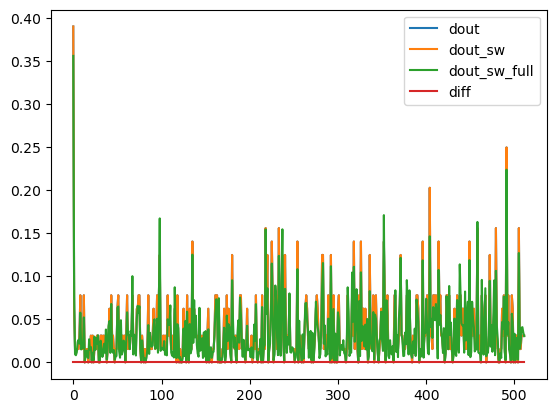

In [33]:
plt.plot(np.mean(np.abs(dout)**2, axis=0), label='dout')
plt.plot(np.mean(np.abs(dout_sw)**2, axis=0), label='dout_sw')
plt.plot(np.mean(np.abs(dout_full)**2, axis=0), label='dout_sw_full')
plt.plot(np.mean(np.abs(dout)**2-np.abs(dout_sw)**2, axis=0), label='diff')
#plt.ylim(-.001,.06)
plt.legend()
plt.show()